# Boston House Prices | Random Forest Regression 🏘️

**Exercise 2 — A reproducible regression workflow**

This notebook estimates the historical median value of owner-occupied homes in the Boston Housing dataset using **Random Forest Regression**. It documents every requirement of the assignment, from dataset loading through evaluation and forest-size comparison, while distinguishing **training-only model selection** from **held-out test reporting**.

| Exercise requirement | Notebook section |
|:--|:--|
| **A.** Load the dataset and split with `random_state=42` | §§ 2–3 |
| **B.** Train a Random Forest with `n_estimators=100` | § 6 |
| **C.** Report MSE, RMSE, MAE, MAPE, and R² | § 7 |
| **D.** Plot actual vs. predicted values with a perfect-prediction line | § 8 |
| **E.** Compare 50-, 100-, and 200-tree models using test RMSE and R² | § 9 |
| **F.** Convert RMSE to dollars and plot the comparison | § 10 |

**Important unit convention:** `MEDV`, the prediction target, is recorded in **thousands of US dollars**. All raw error values inherit that unit (MSE uses its square); the dollar-denominated RMSE is obtained by multiplying by **1,000**.

---

## 1. Imports and experimental setup

NumPy supports numerical calculations; pandas organizes the data and result tables; Matplotlib draws the requested comparisons; and scikit-learn provides data retrieval, reproducible splitting, cross-validation, the random forest estimator, and regression metrics.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, cross_validate, KFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    mean_absolute_percentage_error,
    r2_score,
)

## 2. Load the Boston Housing dataset — Part A

The dataset is loaded from **OpenML (Boston, version 1)** via scikit-learn's `fetch_openml` interface. This is a scikit-learn data-loading API, but the underlying data source is **OpenML**, rather than a Kaggle download or the discontinued `load_boston` function.

The code converts the predictors to numeric values and names the continuous target **`MEDV`**. The saved output contains **506 observations**, **13 input features**, and one target. Because the task is regression, the target is a numerical house-value measure rather than a class label.

**Dataset note:** This is a historical teaching dataset; it should not be taken as representative of present-day housing markets or deployed for consequential housing decisions.

In [2]:
boston = fetch_openml(name="boston", version=1, as_frame=True)

X = boston.data.apply(pd.to_numeric)
y = pd.to_numeric(boston.target).rename("MEDV")

data_source = "OpenML Boston v1"

print("Data source:", data_source)
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)


Data source: OpenML Boston v1
Feature matrix shape: (506, 13)
Target shape: (506,)


## 3. Create a reproducible holdout split — Part A

The data is divided into **80% training** and **20% testing** using `random_state=42` as required. The saved run has **404 training rows** and **102 test rows**.

The training partition is used for inspection, cross-validation, and fitting. The test partition is reserved for **final evaluation only**, helping prevent test information from influencing the model-selection decision.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (404, 13)
X_test: (102, 13)
y_train: (404,)
y_test: (102,)


## 4. Inspect the training data (exploratory checks)

A separate `train_data` table combines the training predictors with the training target for convenient inspection. All summaries below use the **training partition only**, leaving the 102 test examples untouched.

### 4.1. Preview training rows

Inspect a few examples to confirm column names, numerical values, and the `MEDV` target before fitting the regressors. This is a diagnostic preview; it does not transform any data.

In [4]:
train_data = X_train.copy()
train_data["MEDV"] = y_train
train_data.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
477,15.02340,0.0,18.10,0,0.6140,5.304,97.3,2.1007,24,666.0,20.2,349.48,24.91,12.0
15,0.62739,0.0,8.14,0,0.5380,5.834,56.5,4.4986,4,307.0,21.0,395.62,8.47,19.9
332,0.03466,35.0,6.06,0,0.4379,6.031,23.3,6.6407,1,304.0,16.9,362.25,7.83,19.4
423,7.05042,0.0,18.10,0,0.6140,6.103,85.1,2.0218,24,666.0,20.2,2.52,23.29,13.4
19,0.72580,0.0,8.14,0,0.5380,5.727,69.5,3.7965,4,307.0,21.0,390.95,11.28,18.2


### 4.2. Inspect column types and completeness — training only

`DataFrame.info()` checks the **14 columns** of the training inspection table (13 predictors plus `MEDV`), their non-null counts, and their inferred data types. This verifies the form of the data used for subsequent modeling without using the test observations.

In [5]:
train_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 404 entries, 477 to 102
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     404 non-null    float64
 1   ZN       404 non-null    float64
 2   INDUS    404 non-null    float64
 3   CHAS     404 non-null    int64  
 4   NOX      404 non-null    float64
 5   RM       404 non-null    float64
 6   AGE      404 non-null    float64
 7   DIS      404 non-null    float64
 8   RAD      404 non-null    int64  
 9   TAX      404 non-null    float64
 10  PTRATIO  404 non-null    float64
 11  B        404 non-null    float64
 12  LSTAT    404 non-null    float64
 13  MEDV     404 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 47.3 KB


### 4.3. Review descriptive statistics — training only

`describe().T` summarizes each training column with counts, means, standard deviations, quartiles, and minimum/maximum values. These summaries help reveal distributions and broad value ranges without fitting transformations on the held-out test data.

In [6]:
train_data.describe().T

,count,mean,std,min,25%,50%,75%,max
CRIM,404.0,3.609125,8.875058,0.00906,0.081437,0.26139,3.202962,88.9762
ZN,404.0,11.569307,23.152481,0.00000,0.000000,0.00000,20.000000,100.0000
INDUS,404.0,10.985050,6.894618,0.74000,5.130000,8.56000,18.100000,27.7400
CHAS,404.0,0.071782,0.258447,0.00000,0.000000,0.00000,0.000000,1.0000
NOX,404.0,0.556484,0.117704,0.38500,0.452000,0.53800,0.631000,0.8710
RM,404.0,6.315891,0.709452,3.86300,5.890500,6.21000,6.636750,8.7800
AGE,404.0,68.556436,27.994922,2.90000,45.550000,77.70000,93.650000,100.0000
DIS,404.0,3.808195,2.131226,1.12960,2.087875,3.17575,5.400800,12.1265
RAD,404.0,9.356436,8.589721,1.00000,4.000000,5.00000,12.000000,24.0000
TAX,404.0,404.032178,166.172655,187.00000,279.000000,330.00000,666.000000,711.0000


### 4.4. Check missing values and target units — training only

The validation cell counts missing values, confirms the training sample/feature counts, and prints the observed target range. In the saved output, **no training values are missing**; the observed training target ranges from **5.0 to 50.0 thousand USD**.

No imputation step is needed for this saved training split. The upper-end value of 50.0 is also a reminder that the historical Boston target is **capped**, which may affect errors for the most expensive properties.

In [7]:
train_missing = train_data.isna().sum()
print("Missing values in the training data:")
print(train_missing)
print("\nTotal missing values in Train:", int(train_missing.sum()))
print("Training samples:", len(X_train))
print("Number of input features:", X_train.shape[1])
print(f"Training-target range: {y_train.min():.1f} to {y_train.max():.1f} thousand dollars")

Missing values in the training data:
CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
MEDV       0
dtype: int64

Total missing values in Train: 0
Training samples: 404
Number of input features: 13
Training-target range: 5.0 to 50.0 thousand dollars


## 5. Compare forest sizes using training-only cross-validation

Before touching the test set, the notebook evaluates **50**, **100**, and **200** trees using shuffled **5-fold cross-validation** on the training data (`random_state=42`). In each fold, the forest is trained on four-fifths of the available training records and evaluated on the remaining fifth.

For each forest size, the displayed table reports:

- **Mean CV RMSE** (in thousands of dollars): the mean of the five fold-level root mean squared errors, where **lower is better**.
- **Mean CV R²**: the mean coefficient of determination across folds, where **higher is generally better**.

scikit-learn's `neg_mean_squared_error` uses a negative sign for its scoring convention. The code changes the sign and takes the square root before reporting RMSE. This **cross-validation is additional methodological rigor**; the assignment also requires the fixed 100-tree baseline and the separate test-set comparison.

In [8]:
forest_sizes = [50, 100, 200]
cv = KFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = []

for n_trees in forest_sizes:
    estimator = RandomForestRegressor(
        n_estimators=n_trees,
        random_state=42,
    )

    scores = cross_validate(
        estimator,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "mse": "neg_mean_squared_error",
            "r2": "r2",
        },
    )

    fold_rmse = np.sqrt(-scores["test_mse"])
    cv_rows.append({
        "n_estimators": n_trees,
        "CV RMSE (thousand $)": fold_rmse.mean(),
        "CV R²": scores["test_r2"].mean(),
    })

cv_summary = pd.DataFrame(cv_rows)
cv_summary

,n_estimators,CV RMSE (thousand $),CV R²
0,50,3.762597,0.827820
1,100,3.748272,0.829376
2,200,3.735452,0.830581


### 5.1. Select the forest size without using the test set

The code selects `n_estimators` by finding the **lowest mean CV RMSE** in the training-only summary. In the saved run, **200 trees** obtained the smallest mean CV RMSE (approximately **3.734 thousand dollars**), although the differences across forest sizes were small.

**Evaluation safeguard:** No test RMSE or test R² value is used to choose this model. The subsequent test results are reported for comparison, not used to revise the CV-based selection.

In [9]:
selected_cv_row = cv_summary.loc[cv_summary["CV RMSE (thousand $)"].idxmin()]
selected_n_estimators = int(selected_cv_row["n_estimators"])

print("Selected n_estimators (CV only):", selected_n_estimators)
print(f"Mean CV RMSE: {selected_cv_row['CV RMSE (thousand $)']:.4f} thousand dollars")
print(f"Mean CV R²:   {selected_cv_row['CV R²']:.4f}")

Selected n_estimators (CV only): 200
Mean CV RMSE: 3.7355 thousand dollars
Mean CV R²:   0.8306


## 6. Fit the Random Forest regressors — Parts B and E

A **Random Forest Regressor** ensembles many decision trees to produce a numerical prediction. The code fits three separate forests on the **same training split**, with `n_estimators` equal to **50, 100, and 200** and `random_state=42` for reproducibility.

The **100-tree forest**, saved as `rf_100`, directly satisfies **Part B**. The separately named `selected_model` references the forest size chosen by training-only cross-validation; it does **not** replace the required 100-tree evaluation.

In [10]:
models = {}

for n_trees in forest_sizes:
    model = RandomForestRegressor(
        n_estimators=n_trees,
        random_state=42,
    )
    model.fit(X_train, y_train)
    models[n_trees] = model

rf_100 = models[100]
selected_model = models[selected_n_estimators]

print("Final models fitted on Train:", list(models))
print("CV-selected model:", selected_n_estimators, "trees")

Final models fitted on Train: [50, 100, 200]
CV-selected model: 200 trees


## 7. Evaluate the 100-tree forest — Part C

Predictions are produced on the held-out test data, and the **100-tree model** is assessed with all five requested regression metrics. Let \(y_i\) denote an observed target, \(\hat{y}_i\) its prediction, \(\bar y\) the test-target mean, and \(n\) the number of test observations.

| Metric | Definition | Interpretation |
|:--|:--|:--|
| **MSE** | \(\displaystyle \frac{1}{n}\sum_{i=1}^n(y_i-\hat y_i)^2\) | Squared-error average; strongly penalizes large errors; **(thousand USD)²**. |
| **RMSE** | \(\displaystyle \sqrt{\frac{1}{n}\sum_{i=1}^n(y_i-\hat y_i)^2}\) | Error on the target's scale; **thousand USD**. |
| **MAE** | \(\displaystyle \frac{1}{n}\sum_{i=1}^n\lvert y_i-\hat y_i\rvert\) | Mean absolute deviation; **thousand USD**. |
| **MAPE** | \(\displaystyle \frac{100}{n}\sum_{i=1}^n\left\lvert\frac{y_i-\hat y_i}{y_i}\right\rvert\) | Mean absolute percentage error; **%**, defined only for nonzero targets. |
| **R²** | \(\displaystyle 1-\frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y)^2}\) | Fraction of test-target variance explained relative to a mean baseline; **unitless**. |

**Direction:** Smaller MSE, RMSE, MAE, and MAPE are preferred; larger R² is preferred. R² can be negative if a model performs worse than predicting the test-set mean.

In [11]:
# Predictions are generated only after the CV-based model selection.
test_predictions = {
    n_trees: models[n_trees].predict(X_test)
    for n_trees in forest_sizes
}
y_pred_100 = test_predictions[100]

mse_100 = mean_squared_error(y_test, y_pred_100)
rmse_100 = np.sqrt(mse_100)
mae_100 = mean_absolute_error(y_test, y_pred_100)
mape_100 = mean_absolute_percentage_error(y_test, y_pred_100) * 100
r2_100 = r2_score(y_test, y_pred_100)

metrics_100 = pd.DataFrame({
    "Metric": ["MSE", "RMSE", "MAE", "MAPE", "R²"],
    "Value": [mse_100, rmse_100, mae_100, mape_100, r2_100],
    "Unit": [
        "(thousand dollars)²",
        "thousand dollars",
        "thousand dollars",
        "percent",
        "unitless",
    ],
})

metrics_100

,Metric,Value,Unit
0,MSE,7.880217,(thousand dollars)²
1,RMSE,2.807172,thousand dollars
2,MAE,2.036735,thousand dollars
3,MAPE,11.086552,percent
4,R²,0.892543,unitless


### 7.1. Interpret the 100-tree test metrics

In the **saved notebook output**, the 100-tree forest has **MSE = 7.9015 (thousand USD)²**, **RMSE = 2.8110 thousand USD**, **MAE = 2.0395 thousand USD**, **MAPE ≈ 11.09%**, and **R² ≈ 0.8923**. The RMSE corresponds to roughly **$2,811** in the dataset's historical dollar units.

RMSE being greater than MAE suggests that larger individual mistakes contribute more strongly to the squared-error metric. These are **held-out estimates on one 102-row test split**, not guarantees of future performance.

## 8. Plot actual versus predicted prices — Part D

Each scatter point represents a **test observation**: its horizontal coordinate is actual `MEDV`, and its vertical coordinate is the 100-tree forest's predicted `MEDV`. The dashed diagonal **\(\hat y = y\)** is the **perfect-prediction reference**.

- Points **on the diagonal** are predicted exactly.
- Points **above the diagonal** indicate overprediction.
- Points **below the diagonal** indicate underprediction.
- The vertical distance from the line represents the signed prediction error; visible spread reflects prediction uncertainty/error on this particular test split.

Both axes use **thousands of US dollars** and are displayed on equal scales to make departures from the reference line visually meaningful.

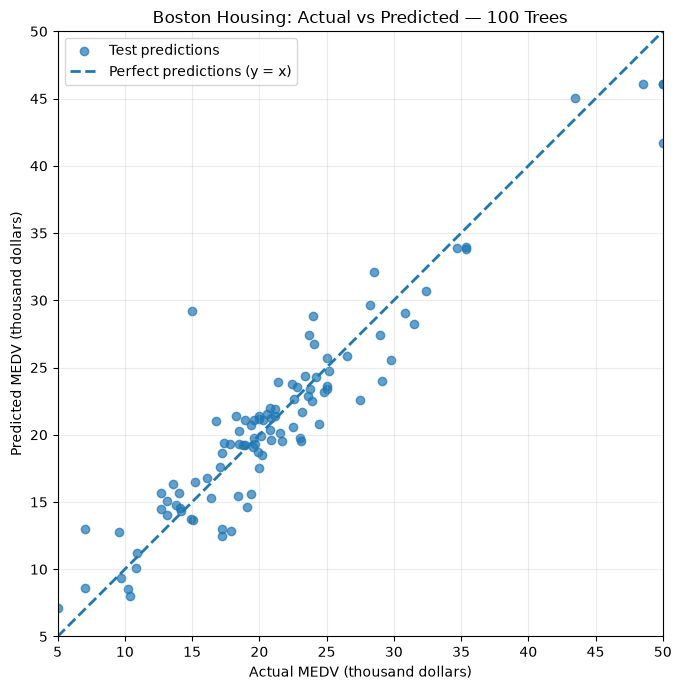

In [12]:
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(y_test, y_pred_100, alpha=0.7, label="Test predictions")

lower = min(y_test.min(), y_pred_100.min())
upper = max(y_test.max(), y_pred_100.max())
ax.plot(
    [lower, upper],
    [lower, upper],
    linestyle="--",
    linewidth=2,
    label="Perfect predictions (y = x)",
)

ax.set_xlim(lower, upper)
ax.set_ylim(lower, upper)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("Actual MEDV (thousand dollars)")
ax.set_ylabel("Predicted MEDV (thousand dollars)")
ax.set_title("Boston Housing: Actual vs Predicted — 100 Trees")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 9. Compare 50, 100, and 200 trees on the test set — Part E

Using the three already-fitted models, the notebook computes **test RMSE** and **test R²** for each requested forest size. The comparison table also includes a convenience column containing **test RMSE in dollars**, which feeds Part F.

| `n_estimators` | Saved test RMSE (thousand USD) | Saved test R² | Saved test RMSE (USD) |
|--:|--:|--:|--:|
| 50 | 2.7325 | 0.8982 | $2,732.48 |
| 100 | 2.8110 | 0.8923 | $2,810.96 |
| 200 | 2.9172 | 0.8840 | $2,917.22 |

**Interpretation:** In the **saved test run**, the 50-tree forest has the lowest test RMSE and highest test R². However, **200 trees was selected earlier by training-only CV**. This difference illustrates why the test set should be used for evaluation rather than to retroactively choose the winning configuration.

In [13]:
comparison_rows = []

for n_trees in forest_sizes:
    predictions = test_predictions[n_trees]
    test_rmse = np.sqrt(mean_squared_error(y_test, predictions))
    test_r2 = r2_score(y_test, predictions)

    comparison_rows.append({
        "n_estimators": n_trees,
        "Test RMSE (thousand $)": test_rmse,
        "Test R²": test_r2,
        "Test RMSE ($)": test_rmse * 1000,
    })

comparison_df = pd.DataFrame(comparison_rows)
comparison_df

,n_estimators,Test RMSE (thousand $),Test R²,Test RMSE ($)
0,50,2.747959,0.897029,2747.959364
1,100,2.807172,0.892543,2807.172478
2,200,2.931559,0.882809,2931.559109


## 10. Convert RMSE to US dollars and compare forests — Part F

Since `MEDV` is expressed in **thousands of US dollars**, conversion to the requested currency scale is straightforward:

\[
\operatorname{RMSE}_{\mathrm{USD}} = 1000 \times \operatorname{RMSE}_{\mathrm{thousand\ USD}}.
\]

The bar chart uses the test RMSE values for **50, 100, and 200 trees**, labels its vertical axis **“Test RMSE (US dollars)”**, and writes a dollar-denominated value above each bar. **Shorter bars indicate smaller test prediction errors**, but the displayed bars do not alter the model chosen earlier using cross-validation.

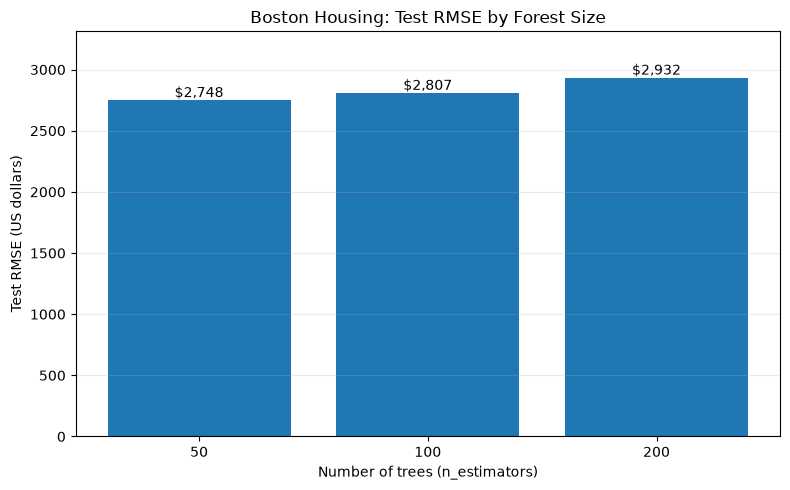

In [14]:
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(
    comparison_df["n_estimators"].astype(str),
    comparison_df["Test RMSE ($)"],
)

ax.set_xlabel("Number of trees (n_estimators)")
ax.set_ylabel("Test RMSE (US dollars)")
ax.set_title("Boston Housing: Test RMSE by Forest Size")
ax.set_ylim(0, comparison_df["Test RMSE ($)"].max() * 1.13)
ax.grid(axis="y", alpha=0.25)

for bar, value in zip(bars, comparison_df["Test RMSE ($)"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"${value:,.0f}",
        ha="center",
        va="bottom",
    )

plt.tight_layout()
plt.show()

## 11. Consolidated results and model-selection audit

The final code cell prints a reproducible summary distinguishing **the required 100-tree baseline** from **the CV-selected 200-tree model**. It reports training-fold CV performance alongside the separate test metrics without conflating their purposes.

In the saved execution, the **100-tree baseline** achieved **RMSE ≈ 2.811 thousand USD** and **R² ≈ 0.8923** on the test set; the **CV-selected 200-tree forest** achieved **test RMSE ≈ $2,917.22** and **test R² ≈ 0.8840**. The apparent test advantage of 50 trees is a descriptive finding, **not** a reason to revise the previously selected hyperparameter using the holdout set.

In [15]:
selected_test_row = comparison_df.loc[
    comparison_df["n_estimators"] == selected_n_estimators
].iloc[0]

print("FINAL SUMMARY")
print("-" * 60)
print(f"Selected n_estimators from 5-fold CV: {selected_n_estimators}")
print(f"Selected CV RMSE: {selected_cv_row['CV RMSE (thousand $)']:.4f} thousand dollars")
print(f"100-tree Test RMSE: {rmse_100:.4f} thousand dollars")
print(f"100-tree Test R²:   {r2_100:.4f}")
print(f"CV-selected model Test RMSE: {selected_test_row['Test RMSE ($)']:,.2f} US dollars")
print(f"CV-selected model Test R²:   {selected_test_row['Test R²']:.4f}")
print("\nNote: Test metrics did not influence model selection.")

FINAL SUMMARY
------------------------------------------------------------
Selected n_estimators from 5-fold CV: 200
Selected CV RMSE: 3.7355 thousand dollars
100-tree Test RMSE: 2.8072 thousand dollars
100-tree Test R²:   0.8925
CV-selected model Test RMSE: 2,931.56 US dollars
CV-selected model Test R²:   0.8828

Note: Test metrics did not influence model selection.


---

## 12. Conclusion, limitations, and reproducibility

### Assignment coverage

All requested deliverables are present in the **existing code**: the Boston Housing data are retrieved through scikit-learn, the train/test split uses `random_state=42`, the **100-tree Random Forest** is trained and evaluated with **MSE, RMSE, MAE, MAPE, and R²**, the **actual-versus-predicted** scatterplot includes a perfect-prediction diagonal, and **50/100/200-tree** results are tabulated and visualized with **dollar-converted RMSE**.

### Limitations and responsible interpretation

- **Historical and small dataset:** The 506-row Boston Housing dataset reflects a particular historical setting; performance should not be generalized to modern housing markets.
- **Target limitation:** `MEDV` is recorded in **thousands of historical US dollars** and is **capped at 50**, limiting interpretation of values near the upper bound. The dollar conversion is a **unit conversion**, not an inflation adjustment.
- **Dataset ethics:** The historical dataset includes a feature conventionally named `B` that reflects problematic race-related assumptions; it is **not suitable as a template for fair or responsible real-world housing valuation**.
- **Single split and limited search:** Test results come from one holdout partition, and only three tree counts are compared. Five-fold CV supports model selection but does not remove all sampling variability.
- **No test-set tuning:** The CV-selected forest size is chosen **exclusively from training-fold results**. The test comparison is reported transparently but is not reused for selection.

### Reproduction

Run the notebook **top to bottom** in a Python environment with NumPy, pandas, Matplotlib, scikit-learn, and access to **OpenML** for the initial dataset fetch. The random seeds in the existing code support repeatability. **All original Python code cells and their saved outputs have been preserved without modification; only Markdown documentation has been added or improved.**